# CODE 1.1: Download and Check the Data

> **Goal:** get the MetroPT-3 data, learn what every column means, check that the file is complete and correct, and save a smaller copy that keeps the type of every column.
>
> - **Input:** `data/raw/MetroPT3(AirCompressor).csv`. If it is not there, this notebook downloads it from UCI.
> - **Output:** `data/processed/metropt3.parquet` (the same table in a smaller file format), and a list of checks. At the end you should see **ALL CHECKS PASSED**.
>
> This notebook never changes the raw data. It only reads it.
>
> **One rule for this notebook.** April to August are the test months: the models are tested there (see the README, "How the models are judged"). So we do not look at the sensor values of those months now. For all months, we only do *technical* checks: is the file complete, are the times in order, are there holes in the time. The sensor values themselves are only shown for February and March.

### Words Used in This Notebook

> - **Sensor / signal:** a sensor measures something on the machine. What it sends out is a signal. In the data, every signal is one column.
> - **Analog signal (a number):** a value on a scale, like a thermometer. For example a pressure of 9.36 bar.
> - **Digital signal (on/off):** only 0 or 1, like a light switch. 1 = on, 0 = off.
> - **bar:** a unit of pressure. 1 bar is about the pressure of the air around us. A car tyre has about 2 bar. This compressor starts pumping when the pressure falls below 8.2 bar.
> - **A (ampere):** a unit of electric current: how much electricity flows.
> - **Hz (hertz):** times per second. 1 Hz = one reading every second.
> - **Timestamp:** the date and time of a reading.
> - **Gap:** a stretch of time without any readings, for example while the train is switched off.
> - **CSV:** a text file with one table row per line. Easy to open, slow to read.
> - **Parquet:** a file format for tables that stores each column together and compressed. It is much smaller than CSV, and it remembers the type of every column: a date stays a date.
> - **SHA-256 fingerprint:** a 64-character code computed from every byte of a file. If one character in the file changes, the code changes completely.

## Import Libraries & Variables

### Import Libraries

> - `os`: works with folders and file paths.
> - `time`: measures how long something takes.
> - `hashlib`: makes the SHA-256 fingerprint of a file.
> - `shutil`, `zipfile`: unzip the downloaded file.
> - `urllib.request`: downloads the file from UCI.
> - `numpy`: works with numbers.
> - `pandas`: reads and works with tables.
> - `matplotlib`: draws charts. `matplotlib.dates` writes the months under a time axis.
> - `tqdm`: shows a progress bar while the file downloads.

In [1]:
import os
import time
import hashlib
import shutil
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the file `requirements.txt`, which sits in the main project folder.
>
> - `ROOT_DIR`: the main project folder.
> - `RAW_DIR`: the original data. We only read from it.
> - `PROCESSED_DIR`: tables that the notebooks make from the raw data.
> - `CSV_FILE`: the data file, exactly as it comes from UCI.
> - `PARQUET_FILE`: the smaller copy that this notebook saves.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

RAW_DIR = os.path.join(ROOT_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
CSV_NAME = "MetroPT3(AirCompressor).csv"
CSV_FILE = os.path.join(RAW_DIR, CSV_NAME)
PARQUET_FILE = os.path.join(PROCESSED_DIR, "metropt3.parquet")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Where the Data Comes From

> MetroPT-3 is shared by the UCI Machine Learning Repository under the license CC BY 4.0 (free to use, with credit to the authors).
>
> - `PAGE_URL`: the page of the dataset.
> - `DATA_URL`: the zip file behind the **Download** button on that page.
> - `ZIP_NAME`: the name the zip file gets when this notebook downloads it.

In [3]:
PAGE_URL = "https://archive.ics.uci.edu/dataset/791/metropt+3+dataset"
DATA_URL = "https://archive.ics.uci.edu/static/public/791/metropt+3+dataset.zip"
ZIP_NAME = "metropt+3+dataset.zip"

#### Expected Values

> The checks below test our copy of the data against these values.
>
> - `EXPECTED_SHA256`: the fingerprint of the CSV file this project was built with (downloaded from UCI in November 2026).
> - `EXPECTED_READINGS`: the description of the dataset (the PDF in the zip, `Data Description_Metro.pdf`) says the data was logged at 1 Hz and has 15,169,480 data points.
> - `KEEP_EVERY`: the file keeps one of every 10 readings (explained further below).
> - `ANALOG_COLUMNS` and `DIGITAL_COLUMNS`: the 7 numbers and the 8 on/off signals, in the order of the description. `DV_eletric` is spelled this way in the file.
> - `EXPECTED_COLUMNS`: all columns of the file in order. The first column has no name in the file; we call it `row_number`.
> - `UNITS`: the unit of each number.
> - `LIMITS`: very wide limits for each number. A value outside them is impossible for this machine, so it would mean a broken sensor or a broken file. These are not "normal ranges".
> - `TIME_FORMAT`: how the timestamps are written, for example `2020-02-01 00:00:10`.
> - `FIRST_DAY`, `LAST_DAY`: the description says the data goes from February to August 2020.
> - `GAP_SECONDS`: a step of more than 60 seconds between two readings counts as a gap.
> - `LOOK_UNTIL`: we only show sensor values from before 1 April 2020 (February and March).

In [4]:
EXPECTED_SHA256 = "db30ccb4ea402e3c8bf2c99db06e288d4f2a772f6928f9dbe26a920d69793e24"
EXPECTED_READINGS = 15169480
KEEP_EVERY = 10

ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
EXPECTED_COLUMNS = ["row_number", "timestamp"] + ANALOG_COLUMNS + DIGITAL_COLUMNS

UNITS = {"TP2": "bar", "TP3": "bar", "H1": "bar", "DV_pressure": "bar", "Reservoirs": "bar", "Oil_temperature": "°C", "Motor_current": "A"}
LIMITS = {"TP2": (-1, 20), "TP3": (-1, 20), "H1": (-1, 20), "DV_pressure": (-1, 20), "Reservoirs": (-1, 20),
          "Oil_temperature": (-30, 150), "Motor_current": (-1, 30)}

TIME_FORMAT = "%Y-%m-%d %H:%M:%S"
FIRST_DAY = "2020-02-01"
LAST_DAY = "2020-09-01"
GAP_SECONDS = 60
LOOK_UNTIL = "2020-04-01"

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`, with the name of the check as the key. If a cell is run twice, the check is stored again under the same name, so it is never counted twice.

In [5]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Download a File

> `download_file()` downloads a file in pieces of 1 MB and shows a progress bar. It first writes to a temporary file that ends with `.part`, and only gives it the real name at the end. So a broken download never looks like a finished file.

In [6]:
def download_file(url, path):
    part_path = path + ".part"
    with urllib.request.urlopen(url, timeout=60) as response, open(part_path, "wb") as f:
        total = int(response.headers.get("Content-Length", 0))
        with tqdm(total=total, unit="B", unit_scale=True, desc="Downloading MetroPT-3") as bar:
            while chunk := response.read(1024 * 1024):
                f.write(chunk)
                bar.update(len(chunk))
    os.replace(part_path, path)

### Unzip Without Folders

> `unzip_flat()` takes every file out of a zip file and puts it straight into `folder`, without the folders inside the zip. So the CSV always ends up at `data/raw/MetroPT3(AirCompressor).csv`.

In [7]:
def unzip_flat(zip_path, folder):
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            name = os.path.basename(member.filename)
            if member.is_dir() or not name:
                continue
            with archive.open(member) as source, open(os.path.join(folder, name), "wb") as target:
                shutil.copyfileobj(source, target)
            print("Unzipped:", name)

### Fingerprint of a File

> `file_sha256()` reads a file in pieces of 1 MB and computes its SHA-256 fingerprint.

In [8]:
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(1024 * 1024):
            digest.update(chunk)
    return digest.hexdigest()

### Show the Files in a Folder

> `show_files()` prints every file in a folder with its size in MB.

In [9]:
def show_files(folder):
    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        if os.path.isfile(path):
            print(f"{name:<36} {os.path.getsize(path) / 1024**2:8.1f} MB")

## Get the Data

### Find or Download the File

> The code looks for the data in this order:
>
> 1. The CSV is already in `data/raw/`: use it.
> 2. A zip file is in `data/raw/` (for example the one from the Download button on the UCI page): unzip it.
> 3. Nothing is there: download the zip from UCI, then unzip it.
>
> If the download fails (no internet, or UCI moved the file), the code stops with a message that says what to do by hand.

In [10]:
os.makedirs(RAW_DIR, exist_ok=True)
zip_files = sorted(name for name in os.listdir(RAW_DIR) if name.lower().endswith(".zip"))

if os.path.isfile(CSV_FILE):
    print("Found the data file:", CSV_NAME)
else:
    if not zip_files:
        print("The data is not in data/raw yet. Downloading it from UCI.")
        try:
            download_file(url=DATA_URL, path=os.path.join(RAW_DIR, ZIP_NAME))
        except Exception as error:
            raise RuntimeError(f"Download failed ({error}). Open {PAGE_URL}, click Download, "
                               "put the zip file in data/raw/ and run this cell again.")
        zip_files = [ZIP_NAME]
    unzip_flat(zip_path=os.path.join(RAW_DIR, zip_files[0]), folder=RAW_DIR)
print()

check("the data file is in data/raw", os.path.isfile(CSV_FILE))

Found the data file: MetroPT3(AirCompressor).csv

PASS  the data file is in data/raw


### What Is in the Raw Folder

> The zip from UCI holds two files: the data (`MetroPT3(AirCompressor).csv`) and its description (`Data Description_Metro.pdf`). The PDF explains every column and lists the 4 air leaks. We use it in this notebook and in notebook 1.2.

In [11]:
show_files(folder=RAW_DIR)

Data Description_Metro.pdf                0.1 MB
MetroPT3(AirCompressor).csv             208.2 MB


### Is It the Right File?

> We compare the fingerprint of your CSV with the fingerprint of the CSV this project was built with. If they are equal, you have exactly the same data, so every notebook gives you exactly the same numbers.
>
> If this check fails, download the file again from UCI. Do not open the CSV in Excel and save it: Excel changes the file (for example the way dates are written).

In [12]:
sha256 = file_sha256(path=CSV_FILE)
print(f"File size: {os.path.getsize(CSV_FILE) / 1024**2:.1f} MB")
print("SHA-256 of your file:        ", sha256)
print("SHA-256 this project expects:", EXPECTED_SHA256, "\n")

check("the file is exactly the one this project was built with (same SHA-256)", sha256 == EXPECTED_SHA256)

File size: 208.2 MB
SHA-256 of your file:         db30ccb4ea402e3c8bf2c99db06e288d4f2a772f6928f9dbe26a920d69793e24
SHA-256 this project expects: db30ccb4ea402e3c8bf2c99db06e288d4f2a772f6928f9dbe26a920d69793e24 

PASS  the file is exactly the one this project was built with (same SHA-256)


## What Is Inside

### The Air System

> A metro train in Porto (Portugal) has an **Air Production Unit**: a compressor that makes compressed air for the brakes, the doors and the suspension. The picture shows the parts in the order the air flows through them, and which column measures which part. It is a simplified drawing based on the description in the PDF.
>
> The compressor works like a bicycle pump that fills a tyre: it pumps until the tanks are full, then rests while the train uses the air. When the pressure falls too low, it starts pumping again. So the compressor runs in **cycles**: pump, rest, pump, rest.

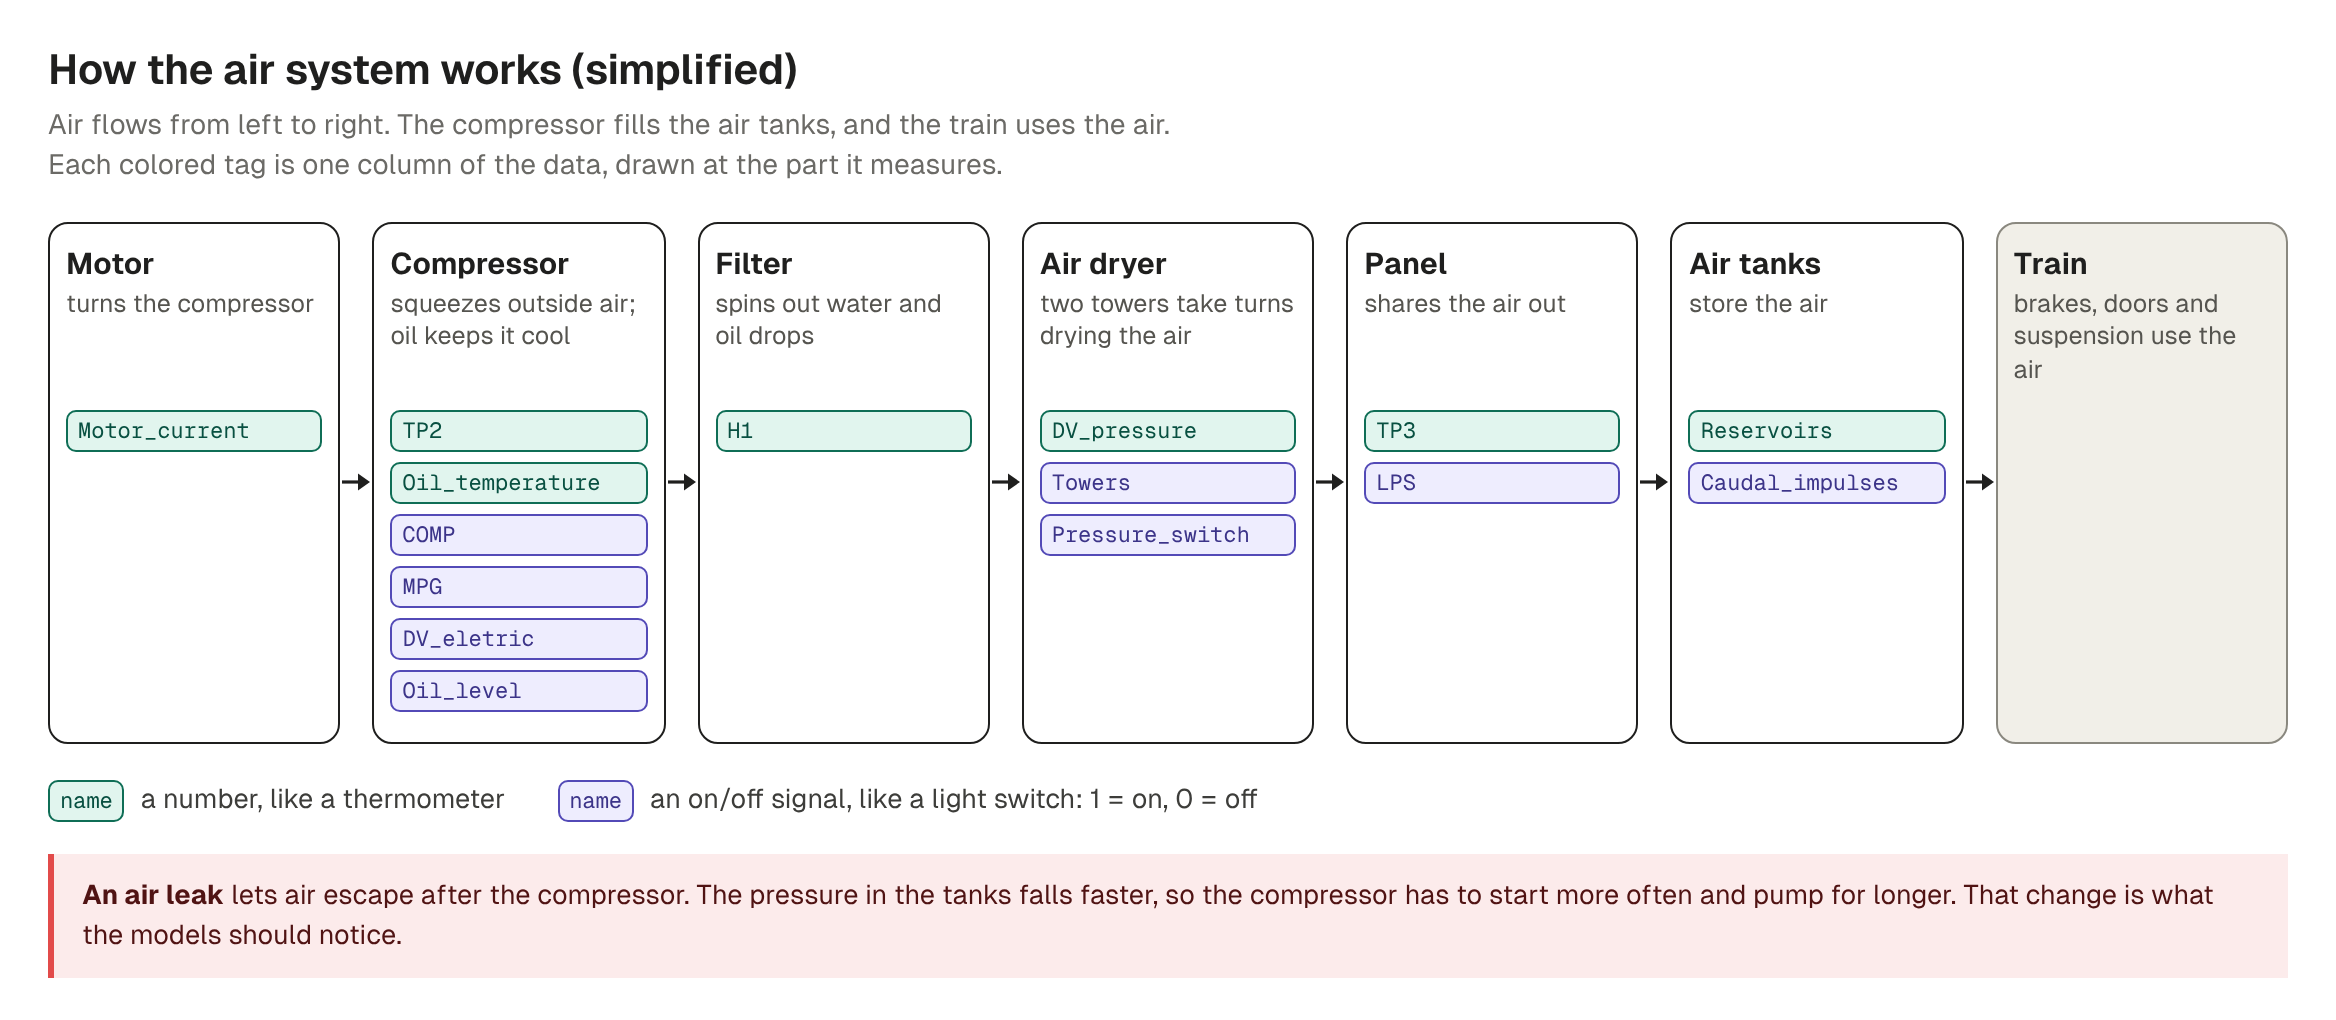

### Read the Table

> `pd.read_csv()` reads the whole CSV into a table (a *DataFrame*) in memory.
>
> The first column has no name in the file, so pandas calls it `Unnamed: 0`. We rename it to `row_number`.

In [13]:
start = time.perf_counter()
df_sensors = pd.read_csv(CSV_FILE)
csv_seconds = time.perf_counter() - start

df_sensors = df_sensors.rename(columns={df_sensors.columns[0]: "row_number"})
print(f"Read {len(df_sensors):,} rows and {df_sensors.shape[1]} columns in {csv_seconds:.1f} seconds")

Read 1,516,948 rows and 17 columns in 0.4 seconds


### The First Rows

> Each row is one **snapshot** of the whole air system: at one moment, all 15 signals are written down together, like a nurse who writes down a patient's temperature, pulse and blood pressure at the same moment.

In [14]:
df_sensors.head()

,row_number,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


### What Each Column Means

> The meaning comes from the description in the PDF. *Number* columns are analog signals, *on/off* columns are digital signals.

| Column | Kind | Unit | Part | What it tells us | Think of it as |
| --- | --- | --- | --- | --- | --- |
| `TP2` | number | bar | compressor | the air pressure the compressor makes: high while it pumps, near 0 when it does not | the gauge on a bicycle pump |
| `TP3` | number | bar | panel | the air pressure at the panel that shares the air out to the train | the water pressure in a pipe at home |
| `H1` | number | bar | filter | the pressure at the filter. It drops when the filter blows out the water and oil it caught | a vacuum cleaner that empties its bag |
| `DV_pressure` | number | bar | air dryer | the pressure drop when a dryer tower blows out its water. Near 0 most of the time | a short "pssst" |
| `Reservoirs` | number | bar | air tanks | the air pressure in the tanks. It should be close to `TP3` | the pressure inside a tyre |
| `Oil_temperature` | number | °C | compressor | how warm the oil of the compressor is | the engine temperature gauge of a car |
| `Motor_current` | number | A | motor | how much electricity the motor uses: about 0 A when off, 4 A when it turns without pumping, 7 A when it pumps, 9 A when it starts | how hard you pedal a bicycle |
| `COMP` | on/off | | compressor | 1 = the air intake is closed: the compressor is off, or turns without pumping | a closed window |
| `DV_eletric` | on/off | | compressor | 1 = the outlet valve is open: the compressor is pumping | an open tap |
| `Towers` | on/off | | air dryer | which of the two towers dries the air now: 0 = tower one, 1 = tower two | two towels: one in use, one drying |
| `MPG` | on/off | | compressor | the switch that starts the pumping when the pressure falls below 8.2 bar. The description says it moves together with `COMP` | a thermostat, but for pressure |
| `LPS` | on/off | | panel | 1 = the pressure fell below 7 bar: low pressure | the low fuel light of a car |
| `Pressure_switch` | on/off | | air dryer | notices when a dryer tower blows out its water | a doorbell that rings at each "pssst" |
| `Oil_level` | on/off | | compressor | about the oil level. The description says 1 = the oil is below the expected level | the oil warning light of a car |
| `Caudal_impulses` | on/off | | pipe into the tanks | pulses from the air that flows into the tanks (*caudal* means "flow") | a water meter |

## Check the Table

### Columns

> The file must have the row number, the timestamp and the 15 signals, in this order.

In [15]:
print("Columns in the file:", list(df_sensors.columns), "\n")
check("17 columns: the row number, the timestamp and the 15 signals, in the expected order", list(df_sensors.columns) == EXPECTED_COLUMNS)

Columns in the file: ['row_number', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses'] 

PASS  17 columns: the row number, the timestamp and the 15 signals, in the expected order


### Why the Row Number Goes Up by 10

> The description says the data was logged at 1 Hz (one reading every second) and has 15,169,480 readings. Our file has 10 times fewer rows. The answer is in the first column: it is the number of each row in the original log, and it goes 0, 10, 20, 30, and so on.
>
> ```
> original log, 1 reading per second:   0  1  2  3  4  5  6  7  8  9  10  11  ...  20  ...
> rows kept in our file:                0                             10            20
> ```
>
> So the file keeps **one of every 10 readings**: about one row every 10 seconds.

In [16]:
expected_rows = EXPECTED_READINGS // KEEP_EVERY
row_steps = df_sensors["row_number"].diff().dropna()
print(f"Rows in the file: {len(df_sensors):,} | readings in the description: {EXPECTED_READINGS:,} | divided by {KEEP_EVERY}: {expected_rows:,}")
print("Row numbers:", df_sensors["row_number"].head(4).tolist(), "...", df_sensors["row_number"].iloc[-1])
print("Steps between two row numbers:", row_steps.value_counts().to_dict(), "\n")

check(f"{expected_rows:,} rows: one of every {KEEP_EVERY} of the {EXPECTED_READINGS:,} readings in the description", len(df_sensors) == expected_rows)
check(f"the row number starts at 0 and goes up by exactly {KEEP_EVERY} every row", df_sensors["row_number"].iloc[0] == 0 and (row_steps == KEEP_EVERY).all())

Rows in the file: 1,516,948 | readings in the description: 15,169,480 | divided by 10: 1,516,948
Row numbers: [0, 10, 20, 30] ... 15169470
Steps between two row numbers: {10.0: 1516947} 

PASS  1,516,948 rows: one of every 10 of the 15,169,480 readings in the description
PASS  the row number starts at 0 and goes up by exactly 10 every row


### Missing Values and Repeated Rows

> - A *missing value* is an empty cell. pandas shows it as `NaN`.
> - A *repeated row* has the same time and the same 15 values as another row. The row number is left out here, because it is always different.

In [17]:
missing = int(df_sensors.isna().sum().sum())
repeated = int(df_sensors.drop(columns="row_number").duplicated().sum())
print("Missing values:", missing)
print("Repeated rows:", repeated, "\n")

check("no missing values", missing == 0)
check("no row appears twice", repeated == 0)

Missing values: 0
Repeated rows: 0 

PASS  no missing values
PASS  no row appears twice


## Check the Time

### Read the Timestamps

> So far the timestamps are just text. `pd.to_datetime()` turns them into real dates and times, so we can sort them, subtract them and group them by day. `errors="coerce"` turns a timestamp that cannot be read into `NaT` (*not a time*), so we can count those.

In [18]:
times = pd.to_datetime(df_sensors["timestamp"], format=TIME_FORMAT, errors="coerce")
unreadable = int(times.isna().sum())
print("Timestamps that could not be read:", unreadable, "\n")

check("every timestamp can be read as a date and time", unreadable == 0)
df_sensors["timestamp"] = times

Timestamps that could not be read: 0 

PASS  every timestamp can be read as a date and time


### Order, Repeats and Range

> The readings must go forward in time, no time may appear twice, and the data must cover February to August 2020, as the description says.

In [19]:
first_time = df_sensors["timestamp"].min()
last_time = df_sensors["timestamp"].max()
print("First reading:", first_time)
print("Last reading: ", last_time)
print(f"That is {(last_time - first_time).total_seconds() / 86400:.1f} days\n")

check("the timestamps go forward in time, oldest first", df_sensors["timestamp"].is_monotonic_increasing)
check("no timestamp appears twice", not df_sensors["timestamp"].duplicated().any())
check("the first reading is on 1 February 2020", first_time.normalize() == pd.Timestamp(FIRST_DAY))
check("the last reading is on or before 1 September 2020", last_time.normalize() <= pd.Timestamp(LAST_DAY))

First reading: 2020-02-01 00:00:00
Last reading:  2020-09-01 03:59:50
That is 213.2 days

PASS  the timestamps go forward in time, oldest first
PASS  no timestamp appears twice
PASS  the first reading is on 1 February 2020
PASS  the last reading is on or before 1 September 2020


### Time Between Two Readings

> `steps` is the number of seconds from each reading to the next one. We count how often each step size appears.

In [20]:
steps = df_sensors["timestamp"].diff().dt.total_seconds()
step_counts = steps.value_counts()
for seconds, count in step_counts.head(6).items():
    print(f"{seconds:4.0f} seconds: {count:>9,} steps ({count / len(steps.dropna()) * 100:5.2f}%)")
print()
for limit in [20, 30, GAP_SECONDS, 3600]:
    print(f"Steps longer than {limit:>4} seconds: {(steps > limit).sum()}")
print()

check("the most common time between two readings is 10 seconds", step_counts.index[0] == 10)

  10 seconds: 1,337,521 steps (88.17%)
   9 seconds:   128,277 steps ( 8.46%)
  12 seconds:    38,321 steps ( 2.53%)
  13 seconds:     7,988 steps ( 0.53%)
  11 seconds:     4,471 steps ( 0.29%)
  21 seconds:        10 steps ( 0.00%)

Steps longer than   20 seconds: 351
Steps longer than   30 seconds: 331
Steps longer than   60 seconds: 331
Steps longer than 3600 seconds: 160

PASS  the most common time between two readings is 10 seconds


> **What we see:** most steps are 10 seconds, and some are 9, 11, 12 or 13 seconds. A logger on a train does not keep perfect time, and these small differences do not matter for us. Above 30 seconds there are no small delays at all: every step is either short or a real gap of more than a minute. That is why `GAP_SECONDS` is 60.

### Gaps: When Nothing Was Recorded

> A gap is a step longer than `GAP_SECONDS`. For each gap we keep the last reading before it, the first reading after it, and its length in hours. These are only times, not sensor values.

In [21]:
gap_rows = steps[steps > GAP_SECONDS].index
gaps = pd.DataFrame({
    "last reading before": df_sensors["timestamp"].shift(1)[gap_rows].values,
    "first reading after": df_sensors["timestamp"][gap_rows].values,
    "hours": (steps[gap_rows] / 3600).values,
})
print(f"{len(gaps)} gaps, {gaps['hours'].sum():.0f} hours in total\n")

lengths = pd.cut(gaps["hours"], bins=[0, 1, 6, 24, 72], labels=["up to 1 hour", "1 to 6 hours", "6 to 24 hours", "more than a day"])
print(lengths.value_counts().sort_index().to_string(), "\n")
print("The 10 longest gaps:")
print(gaps.sort_values("hours", ascending=False).head(10).round({"hours": 1}).to_string(index=False))

331 gaps, 910 hours in total

hours
up to 1 hour       171
1 to 6 hours       128
6 to 24 hours       27
more than a day      5 

The 10 longest gaps:
last reading before first reading after  hours
2020-04-25 01:10:51 2020-04-27 01:12:49   48.0
2020-06-27 10:53:07 2020-06-28 23:07:43   36.2
2020-02-28 23:57:08 2020-03-01 04:00:09   28.1
2020-08-04 07:42:28 2020-08-05 08:23:01   24.7
2020-05-24 00:39:23 2020-05-25 01:14:14   24.6
2020-07-07 15:24:51 2020-07-08 15:20:51   23.9
2020-08-22 19:11:44 2020-08-23 18:51:01   23.7
2020-05-10 00:31:17 2020-05-10 22:48:58   22.3
2020-06-07 14:19:39 2020-06-08 11:48:04   21.5
2020-04-01 13:15:40 2020-04-02 09:59:17   20.7


### When Do the Long Gaps Start?

> For every gap longer than 1 hour, we count the hour of the day when it starts.

In [22]:
long_gaps = gaps[gaps["hours"] > 1]
start_hours = pd.to_datetime(long_gaps["last reading before"]).dt.hour.value_counts().sort_index()
print(f"Gaps longer than 1 hour: {len(long_gaps)}")
print("Starting hour -> number of gaps:")
print(start_hours.to_dict())

Gaps longer than 1 hour: 160
Starting hour -> number of gaps:
{0: 27, 1: 29, 2: 8, 3: 2, 7: 6, 8: 2, 9: 1, 10: 8, 11: 5, 12: 2, 13: 1, 14: 1, 15: 4, 17: 1, 19: 25, 20: 17, 21: 2, 22: 2, 23: 17}


> **What we see:** most long gaps start in the evening or around midnight. A metro train is parked and switched off at night, and the logger stops with it. Some gaps last a day or longer: then the train was not used for a while.
>
> Gaps matter later. In notebook 3.1 we cut the data into 30-minute windows, and a window with a gap inside would jump in time. So windows with a gap are left out.

### Data per Day

> For every day we add up the time that is covered by readings (all steps that are not gaps) and divide it by 24 hours. 100% means the logger ran the whole day. This chart only uses the timestamps, not the sensor values.

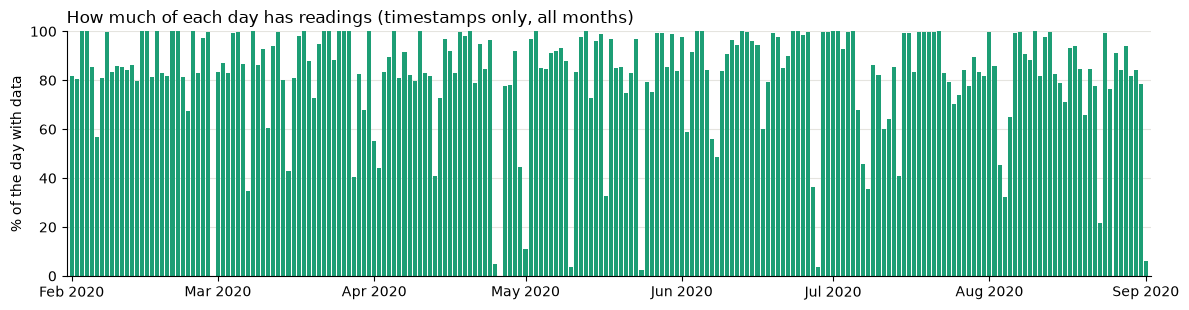

Days without any data: ['29 Feb', '26 Apr']
Days with less than half a day of data: 23 of 214
Average per month (%): {'Feb': 85.0, 'Mar': 85.3, 'Apr': 76.9, 'May': 79.7, 'Jun': 84.7, 'Jul': 82.7, 'Aug': 81.6, 'Sep': 6.1}


In [23]:
day_of_step = df_sensors["timestamp"].dt.floor("D")
covered_seconds = steps.where(steps <= GAP_SECONDS, 0).groupby(day_of_step).sum()
all_days = pd.date_range(FIRST_DAY, last_time.normalize(), freq="D")
coverage = (covered_seconds.reindex(all_days, fill_value=0) / 86400 * 100).clip(upper=100)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(coverage.index, coverage.values, width=0.8, color="#1D9E75")
ax.set_ylim(0, 100)
ax.set_xlim(coverage.index[0] - pd.Timedelta(days=1), coverage.index[-1] + pd.Timedelta(days=1))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("% of the day with data")
ax.set_title("How much of each day has readings (timestamps only, all months)", loc="left")
ax.grid(axis="y", color="#E5E4DF")
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print("Days without any data:", [day.strftime("%d %b") for day in coverage[coverage == 0].index])
print("Days with less than half a day of data:", int((coverage < 50).sum()), "of", len(coverage))
print("Average per month (%):", coverage.groupby(coverage.index.strftime("%b")).mean().reindex(coverage.index.strftime("%b").unique()).round(1).to_dict())

> **What we see:** on most days the logger runs for most of the day, and the nights are the missing part. The last day, 1 September, only has a few hours, because the file ends there.

## Check the Values

### On/Off Signals

> The 8 digital columns may only hold 0 or 1. In the file they are written as `0.0` and `1.0`.

In [24]:
digital_values = sorted(pd.unique(df_sensors[DIGITAL_COLUMNS].to_numpy().ravel()).tolist())
print("Values found in the on/off signals:", digital_values, "\n")
check("the 8 on/off signals are only 0 or 1", set(digital_values) <= {0.0, 1.0})

Values found in the on/off signals: [0.0, 1.0] 

PASS  the 8 on/off signals are only 0 or 1


### Numbers

> Two checks for the 7 analog columns, over all months:
>
> 1. Every value is a real number. `np.isfinite()` is False for "infinity", which can appear when a sensor or a program breaks.
> 2. Every value is inside its very wide `LIMITS`.
>
> Only PASS or FAIL is printed here, not the values themselves, because of the rule at the top of this notebook.

In [25]:
check("the 7 numbers are all real numbers (no infinity)", np.isfinite(df_sensors[ANALOG_COLUMNS].to_numpy()).all())
for column, (low, high) in LIMITS.items():
    check(f"{column} stays between {low} and {high} {UNITS[column]}", df_sensors[column].between(low, high).all())

PASS  the 7 numbers are all real numbers (no infinity)
PASS  TP2 stays between -1 and 20 bar
PASS  TP3 stays between -1 and 20 bar
PASS  H1 stays between -1 and 20 bar
PASS  DV_pressure stays between -1 and 20 bar
PASS  Reservoirs stays between -1 and 20 bar
PASS  Oil_temperature stays between -30 and 150 °C
PASS  Motor_current stays between -1 and 30 A


### Typical Values in February and March

> Now we look at the values, but only in February and March: the months the models learn from and the alarm limits are set on. No air leak was reported in these two months.
>
> - For the numbers: the lowest value, the middle value (*median*: half of the rows are below it), and the highest value.
> - For the on/off signals: in how many % of the rows the signal is 1.

In [26]:
df_feb_mar = df_sensors[df_sensors["timestamp"] < LOOK_UNTIL]
print(f"Rows in February and March: {len(df_feb_mar):,}\n")

numbers = df_feb_mar[ANALOG_COLUMNS].agg(["min", "median", "max"]).T.round(2)
numbers.columns = ["lowest", "middle", "highest"]
numbers.insert(0, "unit", [UNITS[column] for column in ANALOG_COLUMNS])
display(numbers)

switches = (df_feb_mar[DIGITAL_COLUMNS].mean() * 100).round(2).to_frame("% of rows with 1")
display(switches)

Rows in February and March: 445,298



,unit,lowest,middle,highest
TP2,bar,-0.03,-0.01,10.65
TP3,bar,0.73,8.98,10.30
H1,bar,-0.03,8.83,10.27
DV_pressure,bar,-0.03,-0.02,6.53
Reservoirs,bar,0.71,8.98,10.30
Oil_temperature,°C,15.40,58.05,83.12
Motor_current,A,0.02,0.04,9.30


,% of rows with 1
COMP,88.17
DV_eletric,11.85
Towers,94.07
MPG,88.14
LPS,0.12
Pressure_switch,99.77
Oil_level,99.79
Caudal_impulses,82.30


> **What we see:**
>
> - `Motor_current`: the middle value is close to 0 A, so in most rows the motor is off. The compressor only pumps when the tanks need air.
> - `TP2` is also near 0 in most rows, and only goes up while the compressor pumps, as the description says.
> - `TP3` and `Reservoirs` have almost the same values, as the description says.
> - `COMP` and `MPG` have almost the same %, as the description says, and `DV_eletric` is about the opposite: when the intake is closed (`COMP` = 1), the compressor is not pumping (`DV_eletric` = 0).
> - `LPS` is almost never 1: in these healthy months the pressure rarely falls below 7 bar.
> - `Oil_level` is 1 almost all the time. A low oil level for two whole months is unlikely, so in this file 1 probably means that the oil is fine. We keep the column as it is: the models only learn what is normal for it.
>
> Notebook 2.1 looks at these signals over time, for example how one pump cycle looks.

## Save a Smaller Copy

### Smaller Number Types

> pandas stores every column as `float64`: a number with about 16 digits, in 8 bytes. Our sensors give 3 or 4 digits, so `float32` (about 7 digits, 4 bytes) is more than enough, and the on/off signals fit in `int8` (1 byte). The table then needs much less memory.
>
> Before we change anything, we measure the largest change that `float32` makes to any value. We also drop `row_number`: the timestamp already says when each row was taken.

In [27]:
largest_change = max((df_sensors[column] - df_sensors[column].astype("float32").astype("float64")).abs().max() for column in ANALOG_COLUMNS)
print(f"Largest change from float64 to float32: {largest_change:.8f}\n")
check("float32 keeps every number within 0.0001 of the original", largest_change < 0.0001)

Largest change from float64 to float32: 0.00000305

PASS  float32 keeps every number within 0.0001 of the original


In [28]:
memory_before = df_sensors.memory_usage(deep=True).sum() / 1024**2
df_sensors = df_sensors.drop(columns="row_number").astype({**{column: "float32" for column in ANALOG_COLUMNS},
                                                           **{column: "int8" for column in DIGITAL_COLUMNS}})
memory_after = df_sensors.memory_usage(deep=True).sum() / 1024**2
print(f"Memory: {memory_before:.0f} MB before, {memory_after:.0f} MB after\n")
print(df_sensors.dtypes.to_string())

Memory: 197 MB before, 64 MB after

timestamp          datetime64[us]
TP2                       float32
TP3                       float32
H1                        float32
DV_pressure               float32
Reservoirs                float32
Oil_temperature           float32
Motor_current             float32
COMP                         int8
DV_eletric                   int8
Towers                       int8
MPG                          int8
LPS                          int8
Pressure_switch              int8
Oil_level                    int8
Caudal_impulses              int8


### Save as Parquet

> We save the table to `data/processed/metropt3.parquet`, read it back, and compare the two tables cell by cell. The next notebooks read this file instead of the CSV.

In [29]:
os.makedirs(PROCESSED_DIR, exist_ok=True)
df_sensors.to_parquet(PARQUET_FILE, index=False)
df_saved = pd.read_parquet(PARQUET_FILE)

print(f"Saved: {os.path.relpath(PARQUET_FILE, ROOT_DIR)}")
print(f"Size: {os.path.getsize(CSV_FILE) / 1024**2:.0f} MB as CSV, {os.path.getsize(PARQUET_FILE) / 1024**2:.0f} MB as Parquet")
print("Type of the timestamp after reading the file back:", df_saved["timestamp"].dtype, "\n")

check("the saved file has exactly the same table as the one in memory", df_saved.equals(df_sensors))

Saved: data\processed\metropt3.parquet
Size: 208 MB as CSV, 21 MB as Parquet
Type of the timestamp after reading the file back: datetime64[us] 

PASS  the saved file has exactly the same table as the one in memory


## Result

### Final Result

> If every check passed, the data is complete and correct. If a check failed, its name is printed.

In [30]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (24 checks)


## Summary

> - The data comes from one air compressor of a metro train in Porto: 7 numbers (pressures, oil temperature, motor current) and 8 on/off signals, from February to August 2020.
> - The file keeps one of every 10 readings of the original 1 Hz log, so there is one row about every 10 seconds.
> - The file is complete: no missing values, no repeated rows or times, and every value is possible for this machine.
> - There are gaps when the train is switched off, mostly at night. Notebook 3.1 leaves out every window with a gap inside.
> - Sensor values were only shown for February and March. April to August stay closed until the alarm rules are locked.
> - The table is saved as `data/processed/metropt3.parquet`: much smaller than the CSV, and the dates and number types are already set, so the next notebooks can use it right away.
>
> **Next:** `notebooks/1_data_setup/1.2_split_and_label.ipynb`